Shape: (9471, 17)
Columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']

Missing and Sentinel Value Summary:
               null_count  count_sentinel_-200
Date                  114                    0
Time                  114                    0
CO(GT)                114                 1683
PT08.S1(CO)           114                  366
NMHC(GT)              114                 8443
C6H6(GT)              114                  366
PT08.S2(NMHC)         114                  366
NOx(GT)               114                 1639
PT08.S3(NOx)          114                  366
NO2(GT)               114                 1642
PT08.S4(NO2)          114                  366
PT08.S5(O3)           114                  366
T                     114                  366
RH                    114                  366
AH                    114       

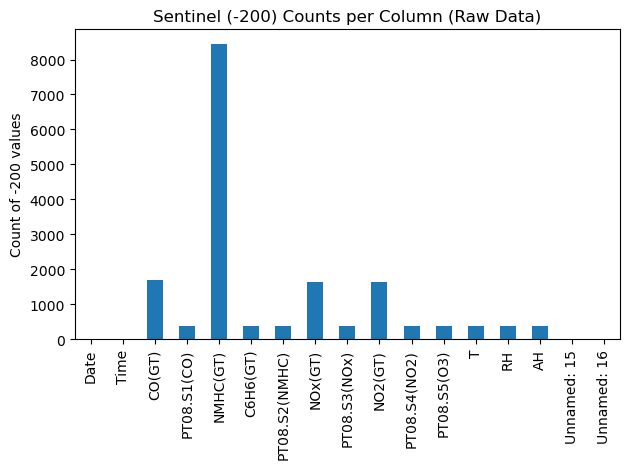

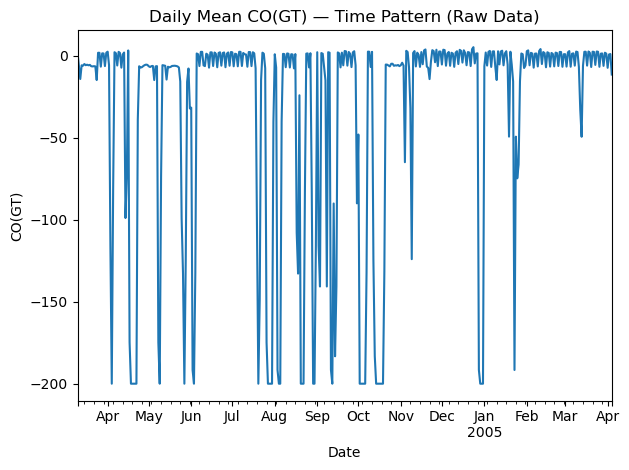

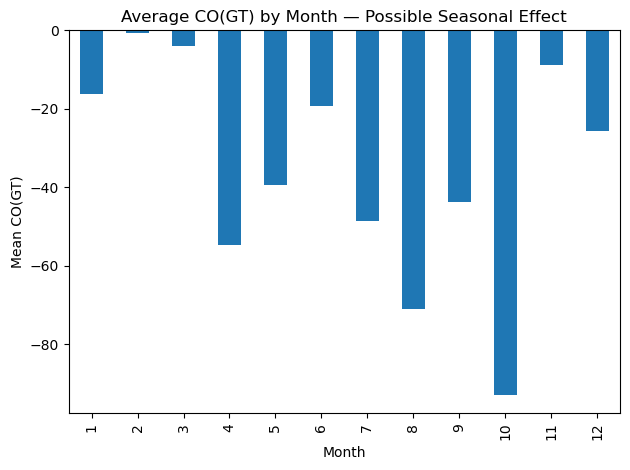

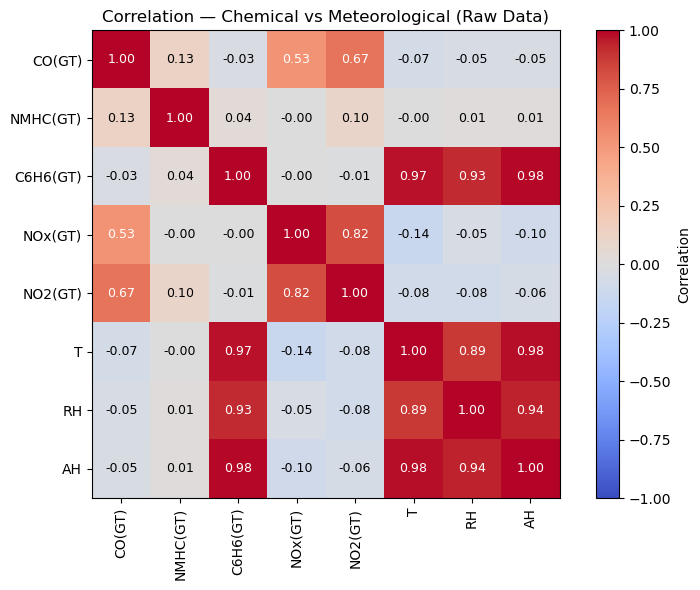

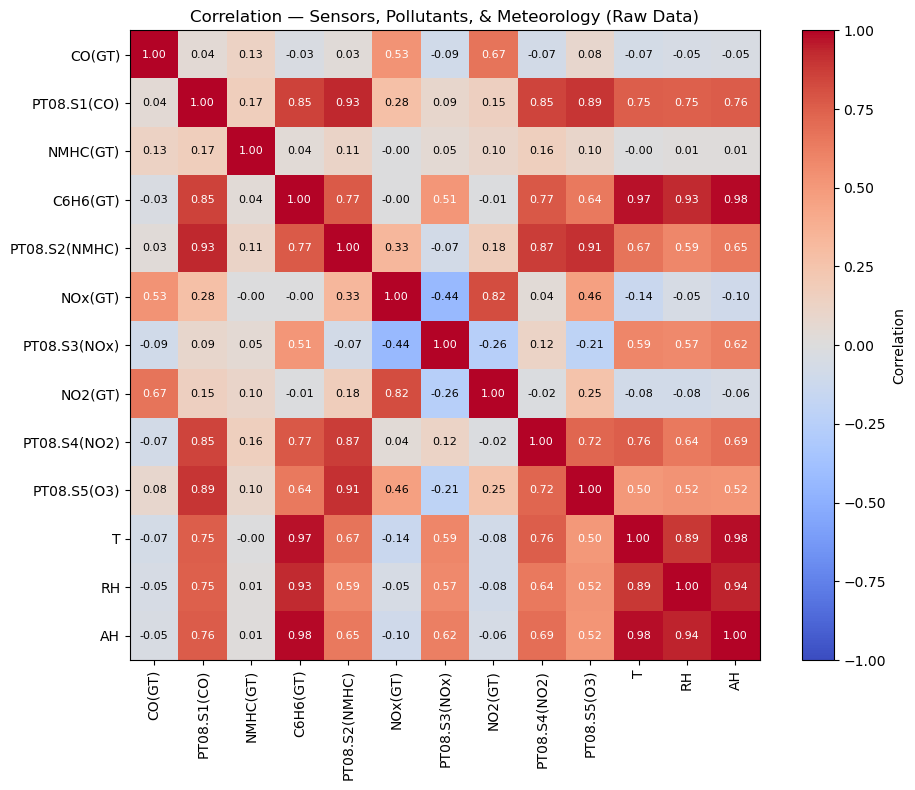

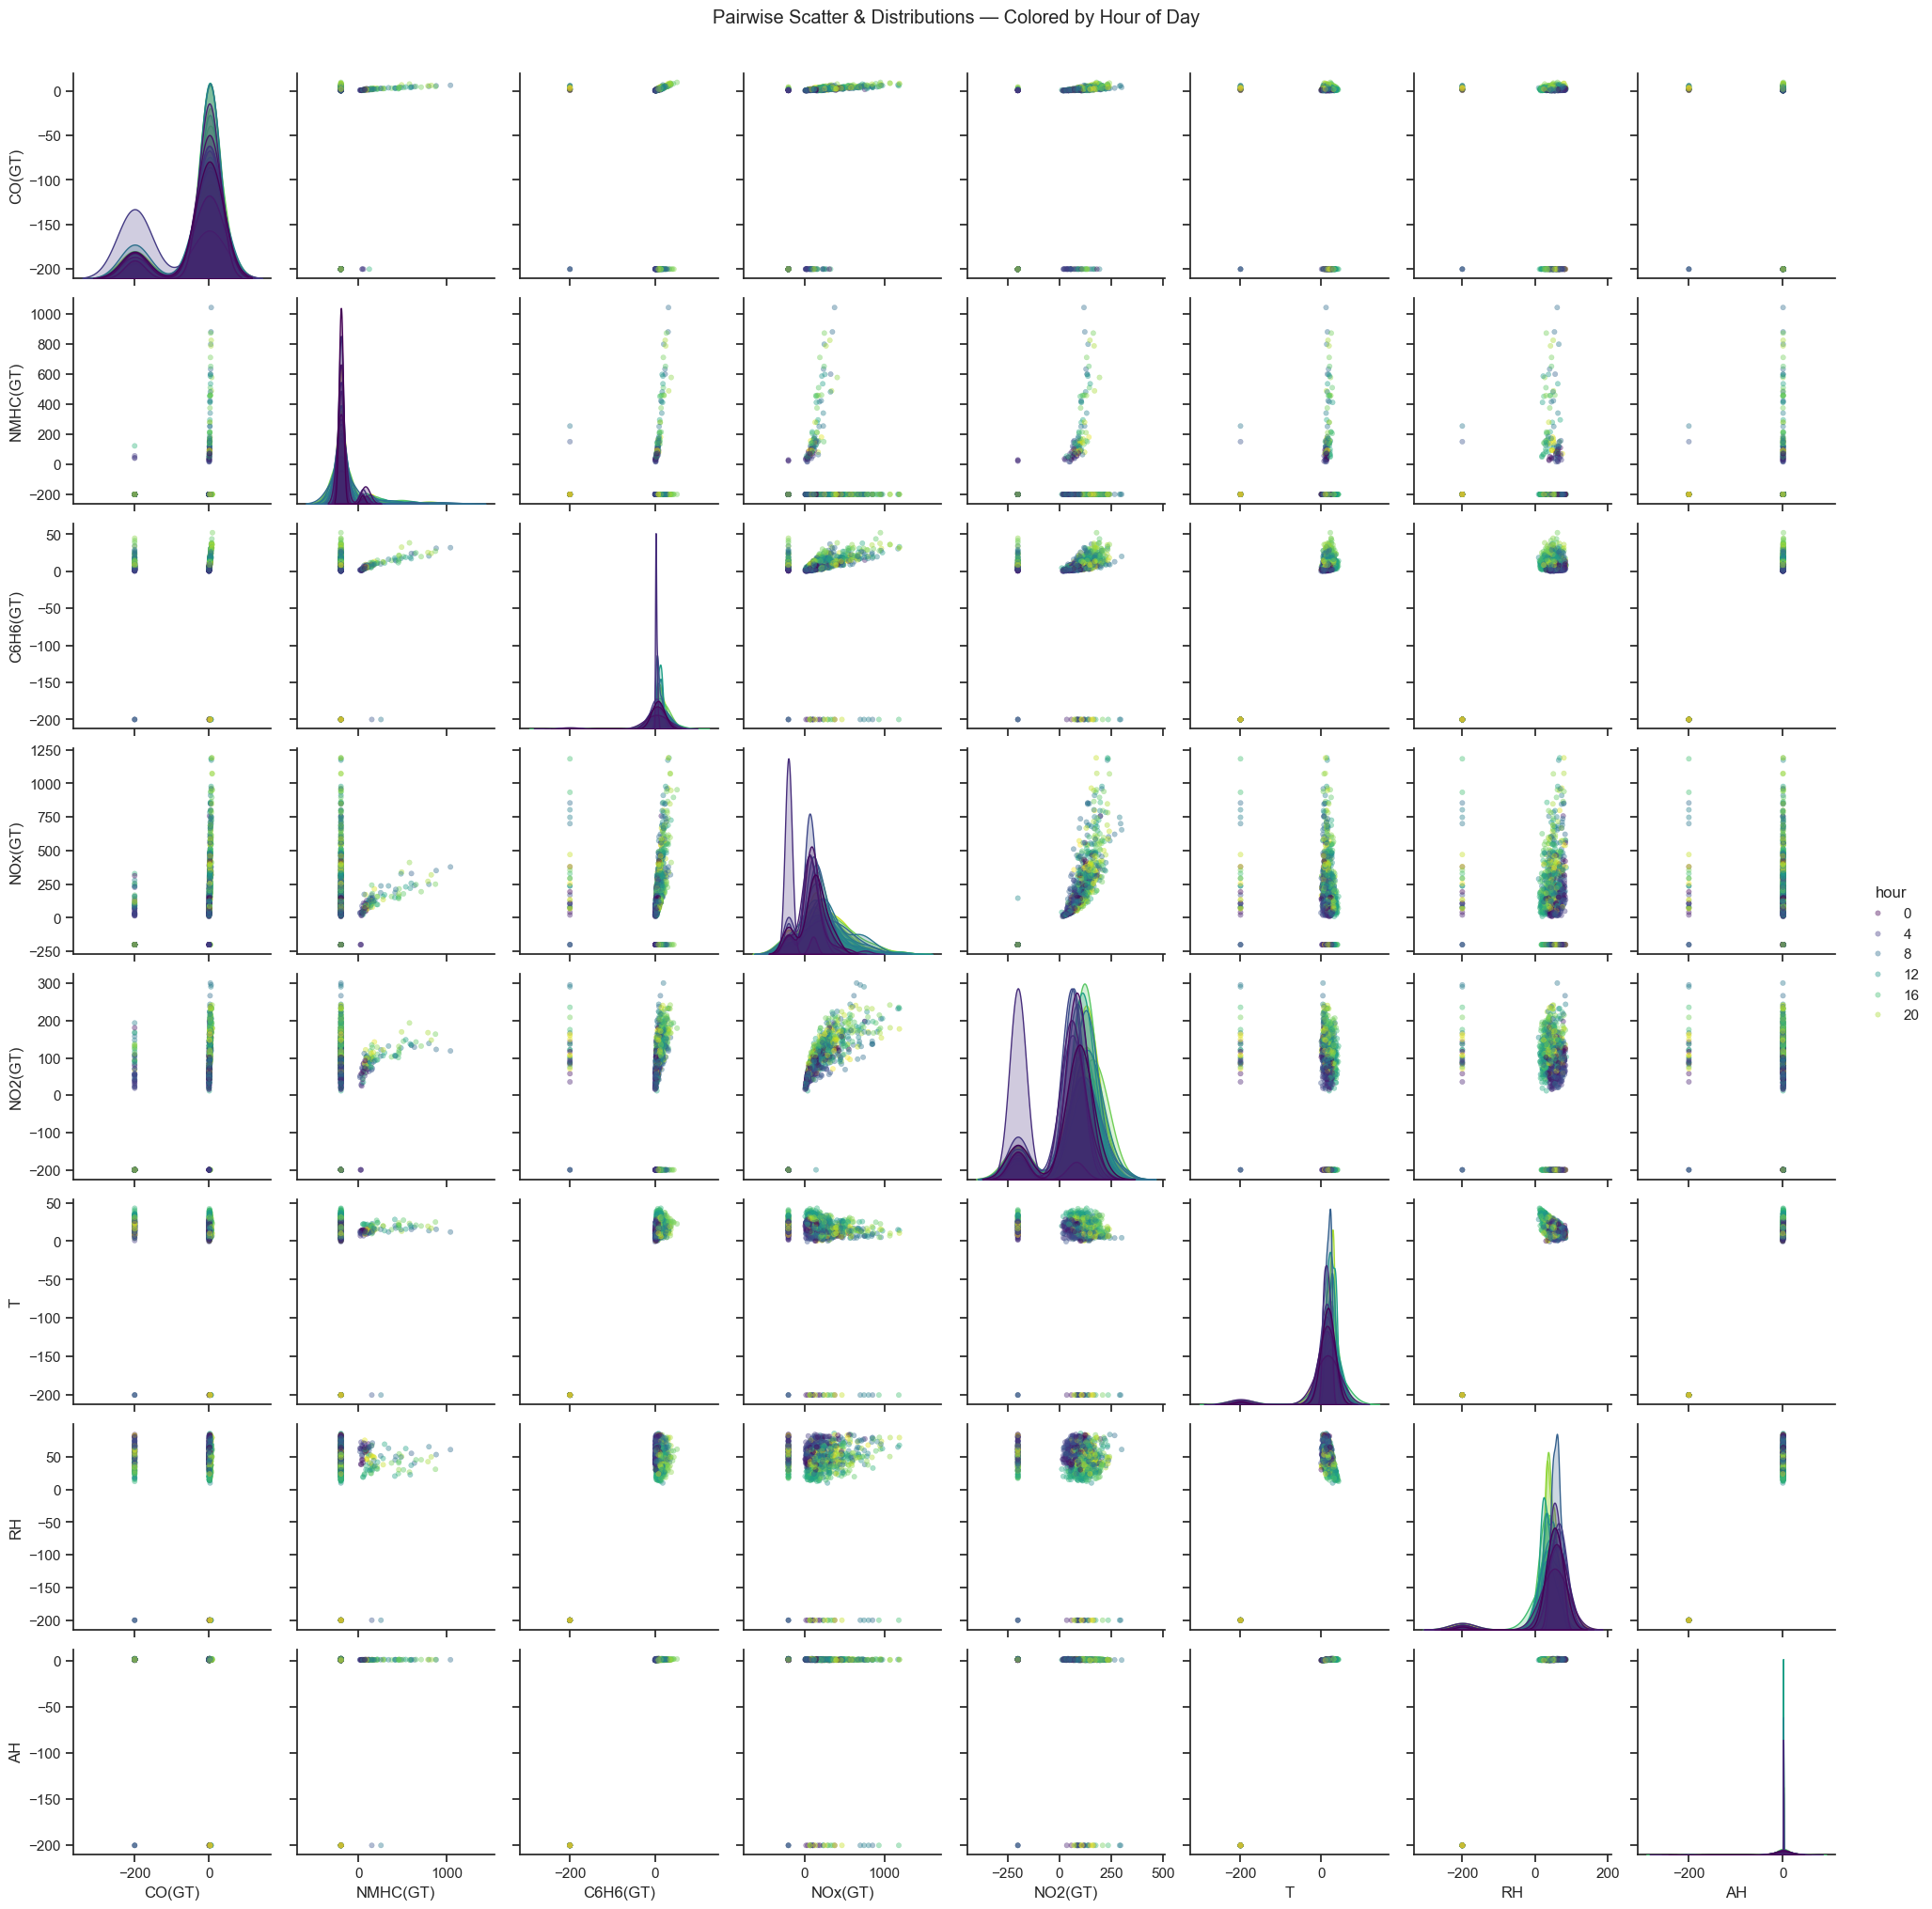

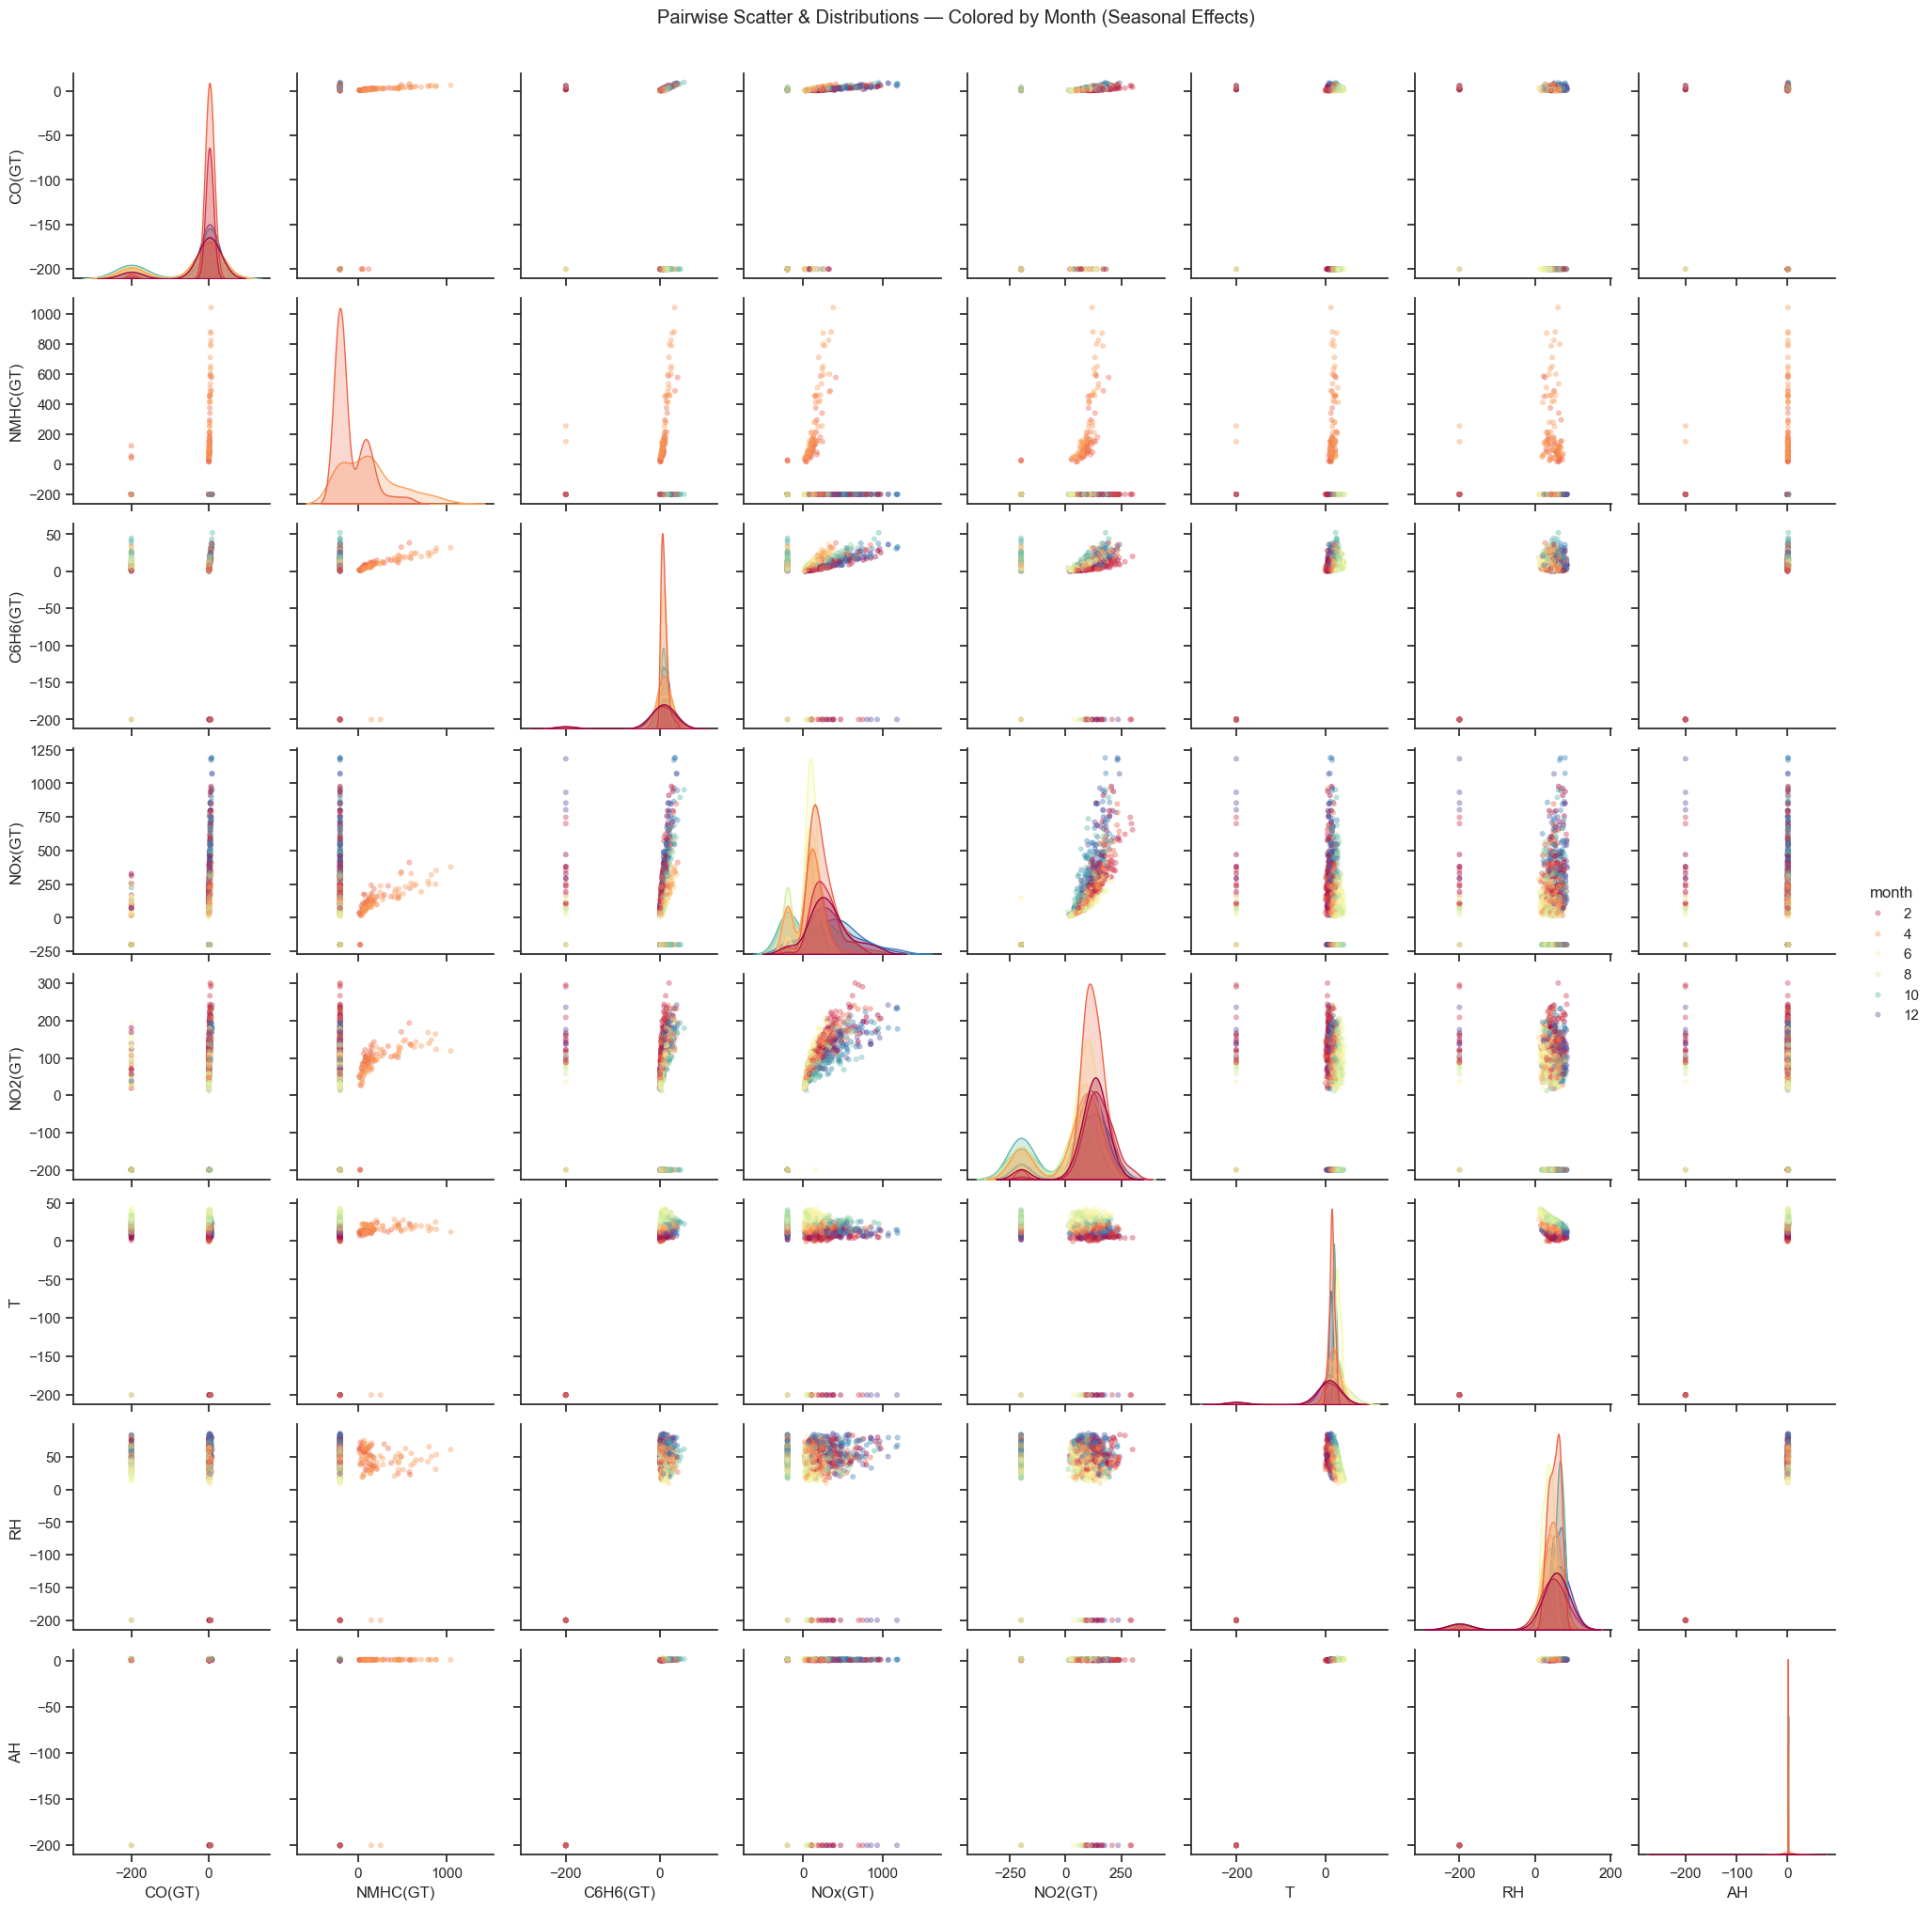

In [ ]:
# =====================================================
# COMP9417 Air Quality Project
# STEP 1 — EDA BEFORE PREPROCESSING
# =====================================================
# Goal:
# Examine time patterns, seasonal effects, correlations among pollutants,
# and relationships between meteorological (T, RH, AH)
# and chemical (CO, NOx, NO2, etc.) variables.
# Identify missing values and data quality issues (e.g., -200 sentinel).
# =====================================================
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ----------- 1. Load raw dataset -----------
df_raw = pd.read_csv("./AirQualityUCI.csv", sep=';', decimal=',')

# Remove empty columns (common in UCI dataset)
df_raw = df_raw.loc[:, ~df_raw.columns.str.fullmatch("")]

print("Shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())


# ----------- 2. Identify missing and sentinel values -----------
sentinel = -200
missing_summary = pd.DataFrame({
    "null_count": df_raw.isna().sum(),
    "count_sentinel_-200": [
        pd.to_numeric(df_raw[c], errors="coerce").eq(sentinel).sum()
        for c in df_raw.columns
    ]
})
print("\nMissing and Sentinel Value Summary:")
print(missing_summary)


# ----------- 3. Parse timestamps (for time and seasonal patterns) -----------
def parse_timestamp(date_str, time_str):
    t = str(time_str).replace(".", ":")
    for fmt in ("%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M"):
        try:
            return datetime.strptime(f"{date_str} {t}", fmt)
        except:
            pass
    return pd.NaT

df_raw["timestamp"] = [
    parse_timestamp(d, t) for d, t in zip(df_raw["Date"], df_raw["Time"])
]
df_raw = df_raw.dropna(subset=["timestamp"]).sort_values("timestamp")


# ----------- 4. Quick time coverage check -----------
print("\nTime range:", df_raw["timestamp"].min(), "→", df_raw["timestamp"].max())
print("Number of hourly records:", len(df_raw))

# Extract time features
df_raw["hour"] = df_raw["timestamp"].dt.hour
df_raw["month"] = df_raw["timestamp"].dt.month
df_raw["year"] = df_raw["timestamp"].dt.year


# ----------- 5. Visualize missingness (-200 counts) -----------
plt.figure()
missing_summary["count_sentinel_-200"].plot(kind="bar", title="Sentinel (-200) Counts per Column (Raw Data)")
plt.ylabel("Count of -200 values")
plt.tight_layout()
plt.show()


# ----------- 6. Time patterns (daily & monthly) -----------
# Convert pollutant values to numeric (keep NaNs for now)
for col in df_raw.columns:
    if col not in ["Date", "Time", "timestamp"]:
        df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

if "CO(GT)" in df_raw.columns:
    daily_co = df_raw.set_index("timestamp")["CO(GT)"].resample("D").mean()
    plt.figure()
    daily_co.plot(title="Daily Mean CO(GT) — Time Pattern (Raw Data)")
    plt.xlabel("Date")
    plt.ylabel("CO(GT)")
    plt.tight_layout()
    plt.show()

# Monthly pattern (mean CO per month)
monthly_co = df_raw.groupby("month")["CO(GT)"].mean()
plt.figure()
monthly_co.plot(kind="bar", title="Average CO(GT) by Month — Possible Seasonal Effect")
plt.xlabel("Month")
plt.ylabel("Mean CO(GT)")
plt.tight_layout()
plt.show()


# ----------- 7A) Correlation: GT pollutants + meteorology (annotated) ----------
chem_cols = ["CO(GT)", "NMHC(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]
met_cols  = ["T", "RH", "AH"]
corr_cols = [c for c in chem_cols + met_cols if c in df_raw.columns]

# Compute correlation on numeric copies (df_raw already coerced above)
corr = df_raw[corr_cols].corr()

plt.figure(figsize=(8, 6))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

# Numeric annotations
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr.iloc[i, j]
        plt.text(j, i, f"{val:.2f}",
                 ha="center", va="center",
                 color=("black" if abs(val) < 0.5 else "white"),
                 fontsize=9)

plt.xticks(np.arange(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(np.arange(len(corr_cols)), corr_cols)
plt.title("Correlation — Chemical vs Meteorological (Raw Data)")
plt.colorbar(im, label="Correlation")
plt.tight_layout()
plt.show()


# ----------- 7B) Correlation: GT + PT08 sensors + meteorology (annotated, safe selection) ----------
# Safe column selection to avoid including the string 'Time'
candidates = []
for c in df_raw.columns:
    if "(GT)" in c or c.startswith("PT08.") or c in {"T", "RH", "AH"}:
        candidates.append(c)

# Coerce to numeric and keep columns that have at least some numeric data
df_num = pd.DataFrame({c: pd.to_numeric(df_raw[c], errors="coerce") for c in candidates})
keep_cols = [c for c in df_num.columns if df_num[c].notna().any()]

corr_full = df_num[keep_cols].corr()

plt.figure(figsize=(10, 8))
im = plt.imshow(corr_full, cmap="coolwarm", vmin=-1, vmax=1)

# Numeric annotations
for i in range(len(keep_cols)):
    for j in range(len(keep_cols)):
        val = corr_full.iloc[i, j]
        plt.text(j, i, f"{val:.2f}",
                 ha="center", va="center",
                 color=("black" if abs(val) < 0.5 else "white"),
                 fontsize=8)

plt.xticks(np.arange(len(keep_cols)), keep_cols, rotation=90)
plt.yticks(np.arange(len(keep_cols)), keep_cols)
plt.title("Correlation — Sensors, Pollutants, & Meteorology (Raw Data)")
plt.colorbar(im, label="Correlation")
plt.tight_layout()
plt.show()


# ----------- 8. Scatter plots — all distributions with time-based color coding -----------
import seaborn as sns

# Variables of interest: pollutants + meteorology
scatter_vars = [
    "CO(GT)", "NMHC(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)",
    "T", "RH", "AH"
]


# Keep only those columns that exist
scatter_vars = [c for c in scatter_vars if c in df_raw.columns]

# Create time features if not already there
if "hour" not in df_raw.columns:
    df_raw["hour"] = df_raw["timestamp"].dt.hour
if "month" not in df_raw.columns:
    df_raw["month"] = df_raw["timestamp"].dt.month

# Random subsample (makes pairplot faster)
sample_df = df_raw[scatter_vars + ["hour", "month"]].sample(n=min(1000, len(df_raw)), random_state=42)

sns.set(style="ticks", font_scale=1.0)

# ----------- 8A. Pairplot color-coded by hour of day -----------
g1 = sns.pairplot(
    sample_df,
    vars=scatter_vars,
    hue="hour",
    palette="viridis",
    diag_kind="kde",
    plot_kws={"alpha": 0.4, "s": 15, "edgecolor": None}
)
g1.fig.suptitle("Pairwise Scatter & Distributions — Colored by Hour of Day", y=1.02)
plt.show()

# ----------- 8B. Pairplot color-coded by month -----------
g2 = sns.pairplot(
    sample_df,
    vars=scatter_vars,
    hue="month",
    palette="Spectral",
    diag_kind="kde",
    plot_kws={"alpha": 0.4, "s": 15, "edgecolor": None}
)
g2.fig.suptitle("Pairwise Scatter & Distributions — Colored by Month (Seasonal Effects)", y=1.02)
plt.show()

